# **02 - Data Exploration**

## **0. Import các thư viện cần thiết và kết nối dữ liệu**

Notebook này thực hiện trọn vẹn giai đoạn **Khám phá dữ liệu, Kiểm toán chất lượng, Tổng hợp quy tắc làm sạch tất định và Kiểm định sau làm sạch** (tương ứng Mục 3.2 của đề bài và tích hợp kết quả từ chuỗi kiểm toán Steps 1–5 của nhóm).

Nguồn dữ liệu đầu vào được kết nối tự động qua module `src/utils.py`, tương thích cả khi chạy cục bộ (`data/processed/step4_clean_v1/` và `data/raw/`) lẫn khi chạy trực tiếp trên Kaggle với dataset đã công bố tại:
- **Cleaned Dataset (`step4_clean_v1`):** https://www.kaggle.com/datasets/chuyenhocielts/myanimelist-clean
- **Raw Source Dataset:** https://www.kaggle.com/datasets/azathoth42/myanimelist

In [1]:
from pathlib import Path
import sys
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "environment.yml").exists()), Path.cwd())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.audit import missing_overview, report_row_change, verify_merge
from src.utils import (
    find_project_root,
    iter_list_parts,
    load_clean_tables,
    resolve_clean_dataset_dir,
    resolve_raw_dataset_dir,
    setup_plot_style,
)

setup_plot_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)

CLEAN_DIR = resolve_clean_dataset_dir(ROOT)
RAW_DIR = resolve_raw_dataset_dir(ROOT)
anime, users, list_parts, clean_logs = load_clean_tables(ROOT)

print(f"Project root       : {ROOT}")
print(f"Cleaned data dir   : {CLEAN_DIR.relative_to(ROOT) if CLEAN_DIR.is_relative_to(ROOT) else CLEAN_DIR}")
print(f"Raw data available : {RAW_DIR is not None}")
print(f"Loaded tables      : anime={anime.shape}, users={users.shape}, parquet_parts={len(list_parts)}")

Project root       : d:\LT cho KHDL\DatasetAnime
Cleaned data dir   : data\processed\step4_clean_v1
Raw data available : True
Loaded tables      : anime=(14478, 66), users=(302673, 35), parquet_parts=27


## **1. Tổng quan về bộ dữ liệu và tính toàn vẹn khóa**

### **1.1. Thông tin cơ bản, quy mô và ý nghĩa mỗi dòng**
Bộ dữ liệu gồm **3 bảng quan hệ** liên kết với nhau:
1. **`AnimeList` (`14,478` dòng × `31` cột gốc, `66` cột sau khi bổ sung các cột `*_clean` và cờ kiểm toán):** Mỗi dòng biểu diễn **một tựa anime** duy nhất trên MyAnimeList.
2. **`UserList` (`302,675` dòng thô -> `302,673` dòng sạch sau khi loại 2 bản sao đổi tên):** Mỗi dòng biểu diễn **một tài khoản người dùng**.
3. **`UserAnimeList` (`80,076,112` dòng thô -> `80,075,053` dòng sạch chia thành 27 phân mảnh Parquet):** Mỗi dòng biểu diễn **một cặp `(username, anime_id)`** ghi lại trạng thái xem và điểm đánh giá của một người dùng đối với một anime.

In [2]:
display(clean_logs["manifest"])
print("\n--- 5 dòng đầu của bảng Anime (các cột cốt lõi) ---")
display(anime[["anime_id", "title_clean", "type_clean", "source_clean", "episodes_clean",
               "duration_minutes_clean", "score_clean", "scored_by", "members", "aired_start_year_clean"]].head())

print("\n--- 5 dòng đầu của bảng Users (các cột cốt lõi) ---")
display(users[["username", "user_id", "gender_clean", "birth_year_clean", "location_clean",
               "user_completed", "user_dropped", "stats_mean_score_clean", "has_list_rows"]].head())

sample_part = pd.read_parquet(list_parts[0]).head()
print("\n--- 5 dòng đầu của phân mảnh Parquet UserAnimeList_clean_001 ---")
display(sample_part)

,file,rows,purpose
0,AnimeList_clean.csv,14478,cleaned anime table
1,UserList_clean.csv,302673,cleaned user table
2,user_anime_list_parts,80075053,"chunked cleaned user-anime table (parquet, cle..."
3,row_count_log.csv,3,every row-count change
4,value_cleaning_log.csv,26,value-level transformations and flags



--- 5 dòng đầu của bảng Anime (các cột cốt lõi) ---


,anime_id,title_clean,type_clean,source_clean,episodes_clean,duration_minutes_clean,score_clean,scored_by,members,aired_start_year_clean
0,11013,Inu x Boku SS,TV,Manga,12.0,24.0,7.63,139250,283882,2012.0
1,2104,Seto no Hanayome,TV,Manga,26.0,24.0,7.89,91206,204003,2007.0
2,5262,Shugo Chara!! Doki,TV,Manga,51.0,24.0,7.55,37129,70127,2008.0
3,721,Princess Tutu,TV,Original,38.0,16.0,8.21,36501,93312,2002.0
4,12365,Bakuman. 3rd Season,TV,Manga,25.0,24.0,8.67,107767,182765,2012.0



--- 5 dòng đầu của bảng Users (các cột cốt lõi) ---


,username,user_id,gender_clean,birth_year_clean,location_clean,user_completed,user_dropped,stats_mean_score_clean,has_list_rows
0,karthiga,2255153,Female,1990.0,"chennai, india",49,0,7.43,True
1,RedvelvetDaisuki,1897606,Female,1995.0,manila,396,0,6.78,True
2,Damonashu,37326,Male,1991.0,"detroit,michigan",195,25,6.15,True
3,bskai,228342,Male,1990.0,"nayarit, mexico",414,5,8.27,True
4,shuzzable,2347781,NaN,NaN,NaN,72,2,9.06,True



--- 5 dòng đầu của phân mảnh Parquet UserAnimeList_clean_001 ---


,username,anime_id,my_status_clean,my_score_clean,my_watched_episodes_clean,my_start_date_clean,my_finish_date_clean,my_start_year_clean,my_finish_year_clean,my_last_updated_clean,my_rewatching_state,my_rewatching_ep_clean,my_tags_clean
0,karthiga,21,1,9,586,NaT,NaT,<NA>,<NA>,2013-03-03 10:52:53,unknown,0,<NA>
1,karthiga,59,2,7,26,NaT,NaT,<NA>,<NA>,2013-03-10 13:54:51,unknown,0,<NA>
2,karthiga,74,2,7,26,NaT,NaT,<NA>,<NA>,2013-04-27 16:43:35,unknown,0,<NA>
3,karthiga,120,2,7,26,NaT,NaT,<NA>,<NA>,2013-03-03 10:53:57,unknown,0,<NA>
4,karthiga,178,2,7,26,NaT,NaT,<NA>,<NA>,2013-03-27 15:59:13,no,0,<NA>


### **1.2. Đối chiếu mô tả tác giả, bẫy nạp dữ liệu `username = "null"` và kiểm tra trùng lặp**

Khi kiểm toán đối chiếu 3 file gốc với mô tả của tác giả trên Kaggle, nhóm phát hiện **3 vấn đề nền tảng về tính toàn vẹn** phải xử lý ngay từ khâu nạp dữ liệu:

1. **Bẫy chuỗi `"null"` của `pandas.read_csv`:** Có đúng **1 người dùng thật mang tên tài khoản là chuỗi `"null"`**, sở hữu **261 dòng** trong `UserAnimeList` (khớp chính xác tổng số anime khai báo trên hồ sơ). Nếu dùng cấu hình mặc định của `pandas`, `"null"` bị biến thành `NaN` và làm đứt gãy phép `join`. Do đó, mọi thao tác đọc CSV bắt buộc dùng `keep_default_na=False, na_values=[""]`.
2. **Khóa `user_id` không duy nhất trong bảng thô (2 tài khoản đổi tên):** Trong `302,675` dòng thô của `UserList.csv` chỉ có `302,673` giá trị `user_id` phân biệt. Hai cặp tài khoản (`Io_Otonashi` / `Edengarde` và `Dojin_` / `DXJIN`) dùng chung `user_id` và lưu hai lần cùng một danh sách xem (**1,059 dòng danh sách trùng khít**). Sau khi loại bỏ 2 bí danh phụ ở Bước 4, cả `username` và `user_id` đều duy nhất 100%, và khóa nối chuẩn giữa các bảng là `username` cùng `anime_id`.
3. **Không xóa bừa bãi `title` trùng tên:** Có 2 bộ anime cùng mang tên `Hinamatsuri` (`anime_id = 35102` là OVA và `36296` là TV series 2018) — đây là hai tác phẩm hoàn toàn khác nhau nên giữ nguyên cả hai và chỉ nối bảng qua `anime_id`.

In [3]:
# Kiểm chứng tính duy nhất của khóa và sự bảo toàn user 'null' trên dữ liệu sạch
assert anime["anime_id"].is_unique, "anime_id phải là khóa chính duy nhất!"
assert users["username"].is_unique, "username phải là khóa chính duy nhất!"
assert users["user_id"].is_unique, "Sau khi loại 2 alias trùng lặp, user_id phải duy nhất!"
assert "null" in set(users["username"]), "User có username='null' phải được bảo toàn!"

dup_titles = anime[anime["title"].duplicated(keep=False)][["anime_id", "title", "type", "status", "aired_string", "scored_by"]]
print("Kiểm tra 2 bộ anime trùng tên 'Hinamatsuri' (khác anime_id và định dạng):")
display(dup_titles)

null_user_row = users[users["username"] == "null"][["username", "user_id", "user_watching", "user_completed", "user_onhold", "user_dropped", "user_plantowatch", "has_list_rows"]]
print("\nKiểm chứng hồ sơ người dùng có username == 'null':")
display(null_user_row)

print("\nNhật ký thay đổi số dòng từ quá trình làm sạch tất định (row_count_log.csv):")
display(clean_logs["row_count_log"] if "row_count_log" in clean_logs else clean_logs["row_log"])

Kiểm tra 2 bộ anime trùng tên 'Hinamatsuri' (khác anime_id và định dạng):


,anime_id,title,type,status,aired_string,scored_by
2984,35102,Hinamatsuri,OVA,Finished Airing,Not available,8
11578,36296,Hinamatsuri,TV,Currently Airing,"Apr 6, 2018 to ?",12470



Kiểm chứng hồ sơ người dùng có username == 'null':


,username,user_id,user_watching,user_completed,user_onhold,user_dropped,user_plantowatch,has_list_rows
124235,null,300142,12,158,8,21,62,True



Nhật ký thay đổi số dòng từ quá trình làm sạch tất định (row_count_log.csv):


,table,rule,before_rows,after_rows,row_delta,reason
0,anime,value corrections only,14478,14478,0,No anime rows are removed; raw values are reta...
1,users,remove duplicate aliases,302675,302673,-2,Io_Otonashi and Dojin_ duplicate Edengarde and...
2,lists,remove duplicate alias rows,80076112,80075053,-1059,The lists for two renamed duplicate accounts a...


### **1.3. Phân nhóm các cột tiềm năng và cột đề xuất loại bỏ / hạn chế sử dụng**

| Bảng | Nhóm cột trọng tâm phục vụ phân tích & ML | Cột loại bỏ hoặc không dùng làm đặc trưng chính (kèm lý do) |
|---|---|---|
| **`AnimeList`** | `anime_id`, `type_clean`, `source_clean`, `episodes_clean`, `duration_minutes_clean`, `rating_clean`, `score_clean`, `scored_by`, `members`, `aired_start_year_clean`, `premiered_clean`, `studio_clean`, `genre_clean`, `related` | `airing` (trùng khít 100% với `status == Currently Airing`); `background` (thiếu 92.7%), `licensor` (thiếu 76.7%), `broadcast` (thiếu 70.5%); các cột ngày trong `aired` thô khi `aired_string` viết thiếu ngày (373 ngày tự điền năm 2018) |
| **`UserList`** | `username`, `gender_clean`, `birth_year_clean`, `account_days_at_crawl`, `stats_mean_score_clean`, `stats_episodes_clean`, `has_list_rows`, `extreme_user` | `access_rank` (**rỗng 100%** ở cả 302,675 dòng — đã loại bỏ); `last_online` (**29.5% = 89,283 user** mang năm mặc định `1900`); ngày/tháng sinh chi tiết (ngày `01/01` xuất hiện 4.36%, gấp 16 lần phân bố đều -> chỉ giữ năm sinh hợp lệ `birth_year_clean`); `stats_rewatched` (chưa kiểm chứng được công thức gốc `[I]`) |
| **`UserAnimeList`** | `username`, `anime_id`, `my_status_clean`, `my_score_clean`, `my_watched_episodes_clean`, `my_finish_date_clean`, `my_finish_year_clean` | `my_tags` (thiếu 94.1% và chứa 53,075 ô placeholder như `undefined`); các giá trị thô `my_score = 0` (chưa chấm điểm, không phải 0 điểm) và mã `my_status` lạ `0, 5, 33, 55` (537 dòng) |

## **2. Phân tích các cột định lượng (Numerical Columns)**

### **2.1. Thống kê mô tả, hình dạng phân phối và kiểm tra phạm vi Min/Max**
Ta tổng hợp thống kê mô tả (trung bình, độ lệch chuẩn, trung vị, tứ phân vị và ngưỡng ngoại lai IQR) cho các biến định lượng quan trọng của bảng `Anime` và `Users`, đồng thời đối chiếu giá trị thô với giá trị sau làm sạch để thấy rõ tác động của các giá trị giữ chỗ (`0`) và lỗi tràn số học.

In [4]:
num_anime_cols = ["episodes_clean", "duration_minutes_clean", "score_clean", "scored_by", "members", "favorites", "aired_start_year_clean"]
desc_anime = anime[num_anime_cols].astype(float).describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T
desc_anime["IQR"] = desc_anime["75%"] - desc_anime["25%"]
desc_anime["outlier_upper_pct"] = [
    round((anime[c].astype(float) > (desc_anime.loc[c, "75%"] + 1.5 * desc_anime.loc[c, "IQR"])).mean() * 100, 2)
    for c in num_anime_cols
]
print("=== Thống kê mô tả các biến định lượng bảng Anime (đã tách giá trị 0 giữ chỗ) ===")
display(desc_anime.round(2))

num_user_cols = ["user_completed", "user_dropped", "user_plantowatch", "user_days_spent_watching_clean",
                 "stats_mean_score_clean", "stats_episodes_clean", "birth_year_clean", "account_days_at_crawl"]
desc_users = users[num_user_cols].astype(float).describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T
print("\n=== Thống kê mô tả các biến định lượng bảng Users ===")
display(desc_users.round(2))

=== Thống kê mô tả các biến định lượng bảng Anime (đã tách giá trị 0 giữ chỗ) ===


,count,mean,std,min,5%,25%,50%,75%,95%,99%,max,IQR,outlier_upper_pct
episodes_clean,13974.0,11.72,44.17,1.00,1.00,1.00,2.0,12.00,50.00,108.00,1818.0,11.00,8.42
duration_minutes_clean,14073.0,26.23,25.50,0.05,1.00,7.00,24.0,30.00,90.00,115.00,231.0,23.00,9.23
score_clean,14124.0,6.30,1.11,1.00,4.32,5.63,6.4,7.08,7.91,8.46,10.0,1.45,0.05
scored_by,14478.0,11460.03,43105.19,0.00,6.00,46.00,501.0,3941.50,58543.80,194311.41,1009477.0,3895.50,16.98
members,14478.0,22966.40,74981.36,0.00,65.00,245.00,1679.5,10379.00,118687.80,361159.94,1456378.0,10134.00,16.04
favorites,14478.0,311.65,2615.55,0.00,0.00,0.00,2.0,23.00,741.45,6780.55,106895.0,23.00,17.54
aired_start_year_clean,14255.0,2003.06,14.91,1917.00,1976.00,1997.00,2008.0,2014.00,2017.00,2018.00,2019.0,17.00,0.00



=== Thống kê mô tả các biến định lượng bảng Users ===


,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
user_completed,302673.0,166.64,239.36,0.0,0.00,28.00,96.00,217.00,565.00,1070.00,11536.00
user_dropped,302673.0,10.55,43.12,0.0,0.00,0.00,2.00,10.00,45.00,114.00,10823.00
user_plantowatch,302673.0,64.04,157.49,0.0,0.00,2.00,20.00,68.00,259.00,614.00,12051.00
user_days_spent_watching_clean,302660.0,59.13,95.07,0.0,0.00,13.63,39.58,79.93,177.40,303.88,9070.35
stats_mean_score_clean,271624.0,7.93,0.98,1.0,6.39,7.37,7.92,8.51,9.63,10.00,10.00
stats_episodes_clean,302514.0,3701.29,6618.00,0.0,0.00,816.00,2384.00,4848.00,10991.00,19791.22,494129.00
birth_year_clean,166484.0,1992.91,4.64,1963.0,1985.00,1990.00,1993.00,1996.00,2000.00,2002.00,2004.00
account_days_at_crawl,302546.0,2252.47,1043.21,1.0,480.00,1425.00,2281.50,3180.00,3746.00,3961.00,4949.00


### **2.2. Phân biệt ngoại lai thực tế (Genuine Outliers) và giá trị bất khả thi (Impossible / Sentinel Values)**

Kết quả kiểm toán chỉ ra sự khác biệt cốt lõi giữa **ngoại lai có thật trong thế giới anime** và **lỗi kỹ thuật**:
- **Ngoại lai hợp lệ cần giữ lại:** `episodes_clean` đạt cực đại `1,818` tập (*Oyako Club*, *Doraemon*, *Sazae-san*) và `members` vượt `1.45 triệu` (*Death Note*, *Shingeki no Kyojin*) là các hiện tượng đại chúng thực tế tạo nên phân phối lệch phải (heavy right-skew), **tuyệt đối không xóa bỏ** mà dùng biến đổi `log1p` hoặc phân nhóm theo mùa (*cour*) khi mô hình hóa.
- **Giá trị bất khả thi & tràn bộ đếm đã khống chế:**
  - Trong bảng thô `UserList`, `stats_episodes` vọt tới **`243,794,881` tập** (~11,000 năm xem liên tục!) và `user_days_spent_watching` tới **`2,601,351` ngày**; một số tài khoản chạm ngưỡng tràn số nguyên 24-bit ($2^{24} = 16,777,216$). Ở bản sạch, các mức vượt ngưỡng vật lý (`>500,000` tập: 32 user; `>10,000` ngày: 13 user) được chuyển sang `NA` và gắn cờ `extreme_user` (314 user).
  - Trong `UserAnimeList`, `my_watched_episodes = 65,535` ($2^{16}-1$: **2,088 dòng**), `my_rewatching_ep = 16,777,215` ($2^{24}-1$: **35 dòng**), và **205,305 dòng** ghi số tập đã xem vượt tổng số tập của bộ anime đều đã được chuyển thành `NA` trong cột `*_clean`.

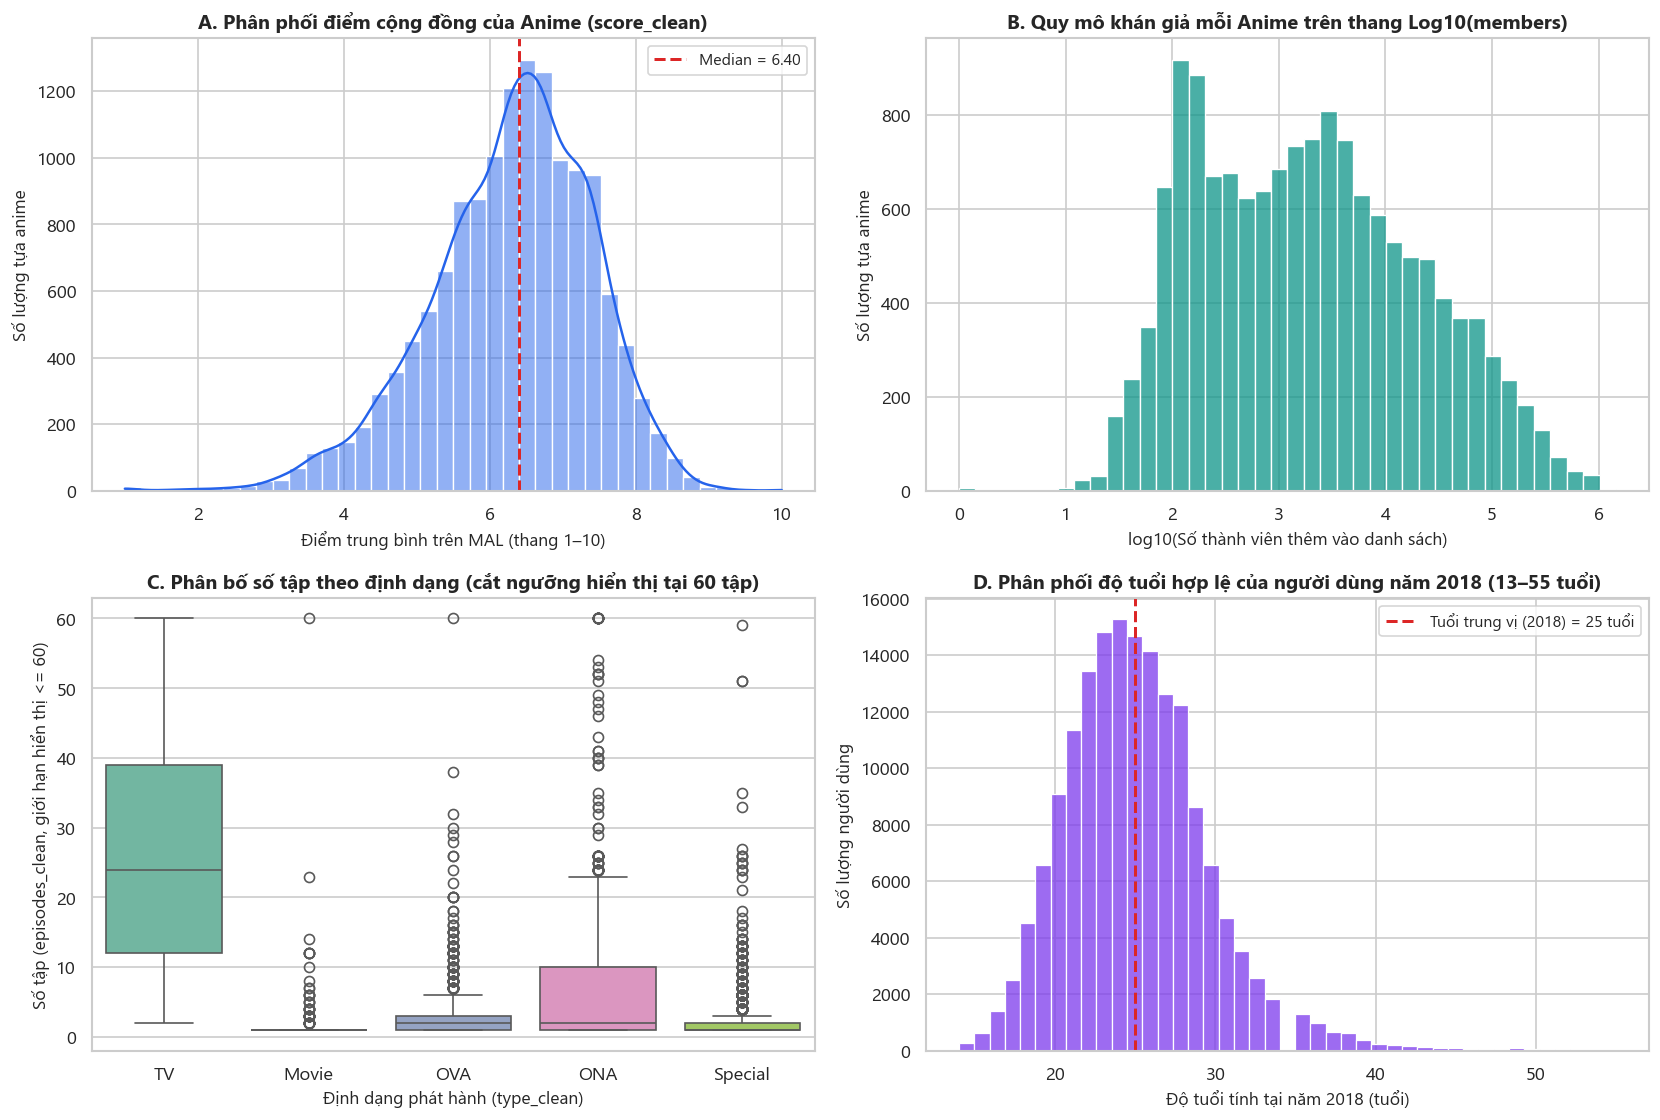

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))

# Panel A: Anime community score distribution
sns.histplot(anime["score_clean"].dropna(), bins=40, kde=True, color="#2563eb", ax=axes[0, 0])
axes[0, 0].axvline(anime["score_clean"].median(), color="#dc2626", linestyle="--", lw=1.8,
                   label=f"Median = {anime['score_clean'].median():.2f}")
axes[0, 0].set_title("A. Phân phối điểm cộng đồng của Anime (score_clean)")
axes[0, 0].set_xlabel("Điểm trung bình trên MAL (thang 1–10)")
axes[0, 0].set_ylabel("Số lượng tựa anime")
axes[0, 0].legend()

# Panel B: Log-scale members distribution showing heavy right tail
sns.histplot(np.log10(anime["members"].clip(lower=1)), bins=40, color="#0d9488", ax=axes[0, 1])
axes[0, 1].set_title("B. Quy mô khán giả mỗi Anime trên thang Log10(members)")
axes[0, 1].set_xlabel("log10(Số thành viên thêm vào danh sách)")
axes[0, 1].set_ylabel("Số lượng tựa anime")

# Panel C: Episode count distribution by primary release formats (clipped at <=100 for visibility + annotation)
sub_ep = anime[anime["type_clean"].isin(["TV", "OVA", "ONA", "Movie", "Special"]) & anime["episodes_clean"].notna()].copy()
sub_ep["ep_clipped"] = sub_ep["episodes_clean"].clip(upper=60).astype(float)
sns.boxplot(data=sub_ep, x="type_clean", y="ep_clipped", hue="type_clean", palette="Set2", legend=False, ax=axes[1, 0])
axes[1, 0].set_title("C. Phân bố số tập theo định dạng (cắt ngưỡng hiển thị tại 60 tập)")
axes[1, 0].set_xlabel("Định dạng phát hành (type_clean)")
axes[1, 0].set_ylabel("Số tập (episodes_clean, giới hạn hiển thị <= 60)")

# Panel D: User mean score vs User birth year / age distribution
valid_age = 2018 - users["birth_year_clean"].dropna().astype(float)
sns.histplot(valid_age, bins=43, color="#7c3aed", ax=axes[1, 1])
axes[1, 1].axvline(valid_age.median(), color="#dc2626", linestyle="--", lw=1.8,
                   label=f"Tuổi trung vị (2018) = {valid_age.median():.0f} tuổi")
axes[1, 1].set_title("D. Phân phối độ tuổi hợp lệ của người dùng năm 2018 (13–55 tuổi)")
axes[1, 1].set_xlabel("Độ tuổi tính tại năm 2018 (tuổi)")
axes[1, 1].set_ylabel("Số lượng người dùng")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

## **3. Phân tích các cột định tính (Categorical Columns) và Hành vi danh sách 80 triệu dòng**

### **3.1. Duyệt một lượt 27 phân mảnh Parquet (`80,075,053` dòng) để kiểm định toàn cục**
Để vừa đo lường phân bố trạng thái xem (`my_status_clean`), phân bố điểm cá nhân (`my_score_clean`), vừa **kiểm định lại toàn bộ 8 quy tắc làm sạch của Bước 4 và các kết luận Bước 5** trên dữ liệu sạch mà không gây tràn bộ nhớ, ta duyệt tuần tự 27 file Parquet đúng một lần.

In [6]:
status_counts = Counter()
score_counts = Counter()
status_rated_counts = Counter()
status_score_sums = Counter()
anime_on_list = Counter()
anime_rated = Counter()
anime_score_sum = Counter()
date_nonnull = Counter()
rule_violations = Counter()

episodes_map = anime.set_index("anime_id")["episodes_clean"]
valid_status_codes = {1, 2, 3, 4, 6}
total_list_rows = 0

stream_cols = [
    "username", "anime_id", "my_status_clean", "my_score_clean",
    "my_watched_episodes_clean", "my_start_date_clean", "my_finish_date_clean",
    "my_start_year_clean", "my_finish_year_clean", "my_rewatching_ep_clean",
]

for part_no, df_part in iter_list_parts(list_parts, columns=stream_cols):
    total_list_rows += len(df_part)

    # Kiểm tra 8 bất biến chất lượng sau làm sạch
    rule_violations["invalid_status"] += int((df_part["my_status_clean"].notna() & ~df_part["my_status_clean"].isin(valid_status_codes)).sum())
    rule_violations["invalid_score"] += int((df_part["my_score_clean"].notna() & ~df_part["my_score_clean"].between(1, 10)).sum())
    rule_violations["watched_sentinel_65535"] += int(df_part["my_watched_episodes_clean"].eq(65_535).sum())
    rule_violations["rewatch_sentinel_24bit"] += int(df_part["my_rewatching_ep_clean"].eq(16_777_215).sum())
    ep_tot = df_part["anime_id"].map(episodes_map)
    rule_violations["watched_exceeds_total"] += int((df_part["my_watched_episodes_clean"].notna() & ep_tot.notna() & df_part["my_watched_episodes_clean"].gt(ep_tot)).sum())
    rule_violations["alias_remnants"] += int(df_part["username"].isin({"Io_Otonashi", "Dojin_"}).sum())

    for k, v in df_part["my_status_clean"].value_counts(dropna=False).items():
        status_counts["Missing/Unknown" if pd.isna(k) else int(k)] += int(v)

    anime_on_list.update(df_part["anime_id"].value_counts().to_dict())

    for dcol in ["my_start_date_clean", "my_finish_date_clean", "my_start_year_clean", "my_finish_year_clean"]:
        date_nonnull[dcol] += int(df_part[dcol].notna().sum())

    rated_sub = df_part.dropna(subset=["my_score_clean"])
    for k, v in rated_sub["my_score_clean"].value_counts().items():
        score_counts[int(k)] += int(v)
    for k, v in rated_sub["my_status_clean"].value_counts(dropna=False).items():
        s_key = "Missing/Unknown" if pd.isna(k) else int(k)
        status_rated_counts[s_key] += int(v)
    for k, v in rated_sub.groupby(rated_sub["my_status_clean"].fillna(-1))["my_score_clean"].sum().astype(float).items():
        s_key = "Missing/Unknown" if k == -1 else int(k)
        status_score_sums[s_key] += float(v)

    anime_rated.update(rated_sub["anime_id"].value_counts().to_dict())
    anime_score_sum.update(rated_sub.groupby("anime_id")["my_score_clean"].sum().astype(float).to_dict())

assert total_list_rows == 80_075_053, f"Sai tổng dòng: {total_list_rows:,}"
assert not any(rule_violations.values()), f"Phát hiện vi phạm làm sạch: {dict(rule_violations)}"

print(f"Đã kiểm định thành công {total_list_rows:,} dòng trên {len(list_parts)} phần Parquet!")
print("Số vi phạm trên toàn bộ các quy tắc làm sạch:", dict(rule_violations))

Đã kiểm định thành công 80,075,053 dòng trên 27 phần Parquet!
Số vi phạm trên toàn bộ các quy tắc làm sạch: {'invalid_status': 0, 'invalid_score': 0, 'watched_sentinel_65535': 0, 'rewatch_sentinel_24bit': 0, 'watched_exceeds_total': 0, 'alias_remnants': 0}


### **3.2. Phân bố các biến phân loại và hành vi chấm điểm theo trạng thái xem**

,Trạng thái,Số dòng,Tỷ trọng (%),Số dòng đã chấm điểm,Tỷ lệ chưa chấm (%),Điểm TB (chỉ dòng đã chấm)
0,2 - Completed (Đã xem xong),50444761,63.00,42398863,15.95,7.57
1,6 - Plan to Watch (Dự định xem),19391920,24.22,238166,98.77,7.85
2,1 - Watching (Đang xem),4057742,5.07,1273124,68.62,7.95
3,4 - Dropped (Bỏ dở),3194305,3.99,1506803,52.83,4.95
4,3 - On Hold (Tạm ngưng),2985788,3.73,941166,68.48,7.27
5,"Mã lạ (0, 5, 33, 55 -> NA)",537,0.00,79,85.29,8.92


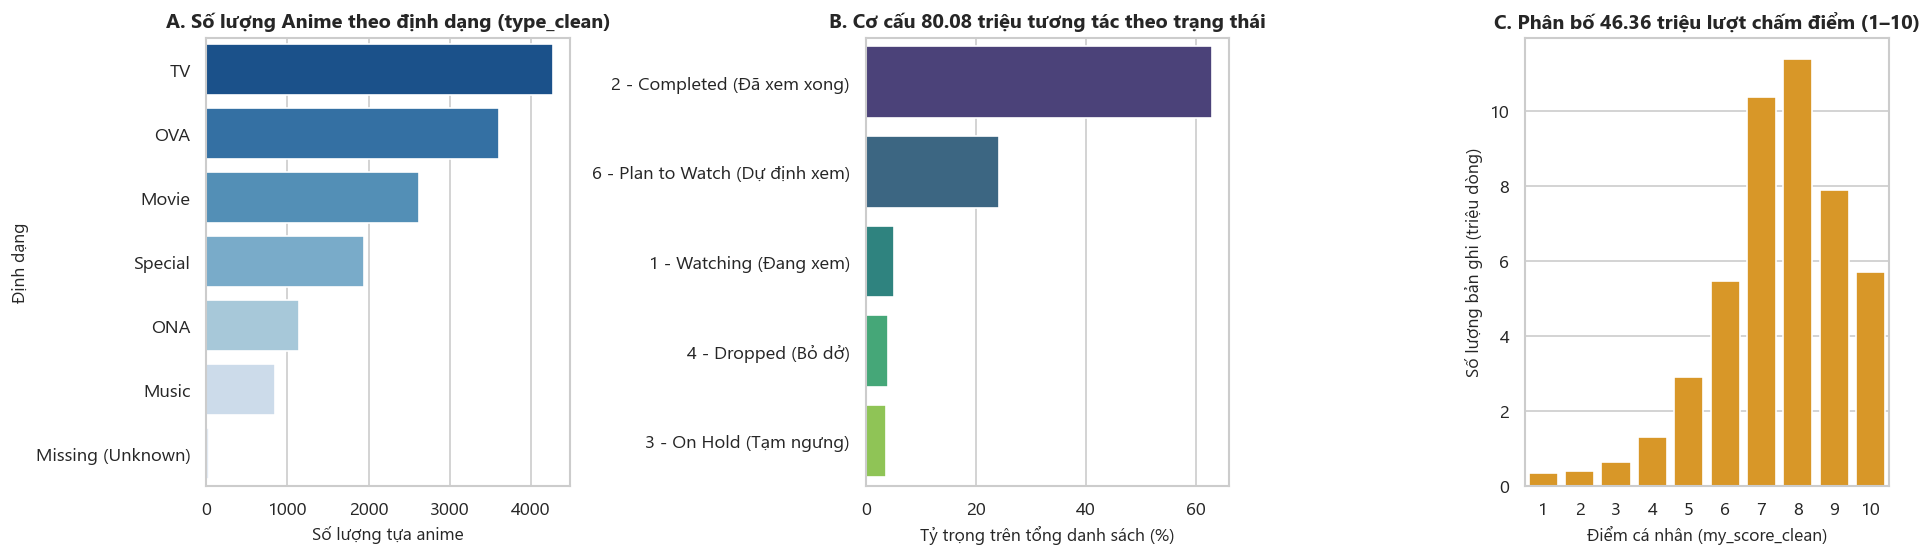

In [7]:
status_labels = {
    2: "2 - Completed (Đã xem xong)",
    6: "6 - Plan to Watch (Dự định xem)",
    1: "1 - Watching (Đang xem)",
    4: "4 - Dropped (Bỏ dở)",
    3: "3 - On Hold (Tạm ngưng)",
    "Missing/Unknown": "Mã lạ (0, 5, 33, 55 -> NA)",
}
status_summary = []
for code_k in [2, 6, 1, 4, 3, "Missing/Unknown"]:
    n_rows = status_counts[code_k]
    n_rated = status_rated_counts[code_k]
    mean_sc = status_score_sums[code_k] / n_rated if n_rated > 0 else np.nan
    status_summary.append({
        "Trạng thái": status_labels[code_k],
        "Số dòng": n_rows,
        "Tỷ trọng (%)": round(n_rows / total_list_rows * 100, 2),
        "Số dòng đã chấm điểm": n_rated,
        "Tỷ lệ chưa chấm (%)": round((1 - n_rated / n_rows) * 100, 2) if n_rows else np.nan,
        "Điểm TB (chỉ dòng đã chấm)": round(mean_sc, 2) if pd.notna(mean_sc) else np.nan,
    })
status_summary_df = pd.DataFrame(status_summary)
display(status_summary_df)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Plot 1: Anime release formats & top sources
type_vc = anime["type_clean"].fillna("Missing (Unknown)").value_counts()
sns.barplot(x=type_vc.values, y=type_vc.index, hue=type_vc.index, palette="Blues_r", legend=False, ax=axes[0])
axes[0].set_title("A. Số lượng Anime theo định dạng (type_clean)")
axes[0].set_xlabel("Số lượng tựa anime")
axes[0].set_ylabel("Định dạng")

# Plot 2: User list status distribution & mean score
plot_st = status_summary_df.iloc[:5].copy()
sns.barplot(data=plot_st, x="Tỷ trọng (%)", y="Trạng thái", hue="Trạng thái", palette="viridis", legend=False, ax=axes[1])
axes[1].set_title("B. Cơ cấu 80.08 triệu tương tác theo trạng thái")
axes[1].set_xlabel("Tỷ trọng trên tổng danh sách (%)")
axes[1].set_ylabel("")

# Plot 3: Distribution of explicit ratings 1..10
sc_series = pd.Series({k: score_counts[k] / 1e6 for k in range(1, 11)})
sns.barplot(x=sc_series.index.astype(str), y=sc_series.values, color="#f59e0b", ax=axes[2])
axes[2].set_title("C. Phân bố 46.36 triệu lượt chấm điểm (1–10)")
axes[2].set_xlabel("Điểm cá nhân (my_score_clean)")
axes[2].set_ylabel("Số lượng bản ghi (triệu dòng)")

plt.tight_layout()
plt.show()

**Nhận xét quan trọng về biến phân loại & hành vi:**
- **Mất cân bằng trạng thái và mẫu số phân tích:** `Completed` chiếm **63.00%** (`50.44 triệu` dòng) và `Plan to Watch` chiếm **24.22%** (`19.39 triệu` dòng, trong đó **98.77%** chưa chấm điểm vì chưa xem). Vì vậy, khi tính tỷ lệ hoàn thành hoặc bỏ dở ở Câu hỏi 1–5, **bắt buộc loại `Plan to Watch` khỏi mẫu số** và chỉ xét nhóm đã thực sự bắt đầu xem.
- **Thiên lệch điểm số theo kết cục xem:** Điểm trung bình trên toàn bộ `46,358,201` dòng có chấm điểm là **7.49** (điểm phổ biến nhất là **8** với `11.39 triệu` dòng), nhưng người `Dropped` chấm trung bình chỉ **4.95** (với 52.8% không chấm điểm) so với **7.57** ở nhóm `Completed` (chỉ 16.0% không chấm điểm).
- **Nhãn hiếm và gộp nhóm:** Ở cột `source_clean`, `4,210` anime mang nhãn gốc `Unknown` đã chuyển sang thiếu, còn các nguồn nhỏ như `Picture book`, `Card game`, `Radio`, `Digital manga` sẽ được giữ nguyên hoặc gộp nhóm tần suất tối thiểu (`min_frequency`) trong Pipeline học máy.

## **4. Phân tích dữ liệu khuyết thiếu (Missing Data) và Tổng hợp Quyết định Làm sạch**

### **4.1. Đánh giá tỷ lệ thiếu thực sự (sau khi giải mã Placeholder) và cơ chế thiếu**
Nhiều giá trị thiếu trong dữ liệu thô bị che giấu dưới dạng chuỗi (`"Unknown"`, `"None"`, `"0000-00-00"`, `"[]"`), số `0` (`score = 0`, `episodes = 0`, `my_score = 0`) hoặc ngày mặc định (`1900`, `1930`). Bảng và biểu đồ dưới đây phản ánh **tỷ lệ thiếu thực chất** trên các cột `*_clean`.

,missing_count,missing_pct,dtype,table
background_clean,13421,92.70,object,AnimeList_clean
my_start_date_clean,69491601,86.78,datetime64,UserAnimeList_clean
broadcast_clean,12448,85.98,object,AnimeList_clean
my_finish_date_clean,66955355,83.62,datetime64,UserAnimeList_clean
licensor_clean,11105,76.70,object,AnimeList_clean
premiered_clean,10382,71.71,object,AnimeList_clean
location_clean,146183,48.30,object,UserList_clean
birth_year_clean,136189,45.00,float64,UserList_clean
producer_clean,6190,42.75,object,AnimeList_clean
my_score_clean (0 -> NA),33716852,42.11,Int8,UserAnimeList_clean



--- Bảng thống kê 25 quy tắc biến đổi giá trị ở Bước 4 (value_cleaning_log.csv) ---


,rule,count
0,anime.episodes_zero_to_missing,504
1,anime.low_raters,4789
2,anime.not_yet_aired_with_completed_rows,6
3,anime.popularity_zero_to_missing,9
4,anime.rank_zero_to_missing,9
5,anime.score_zero_to_missing,354
6,anime.text_placeholder_to_missing,7653
7,lists.completed_episode_count_inferred,284297
8,lists.date_full_invalid_to_missing,74325
9,lists.date_year_partial,756482


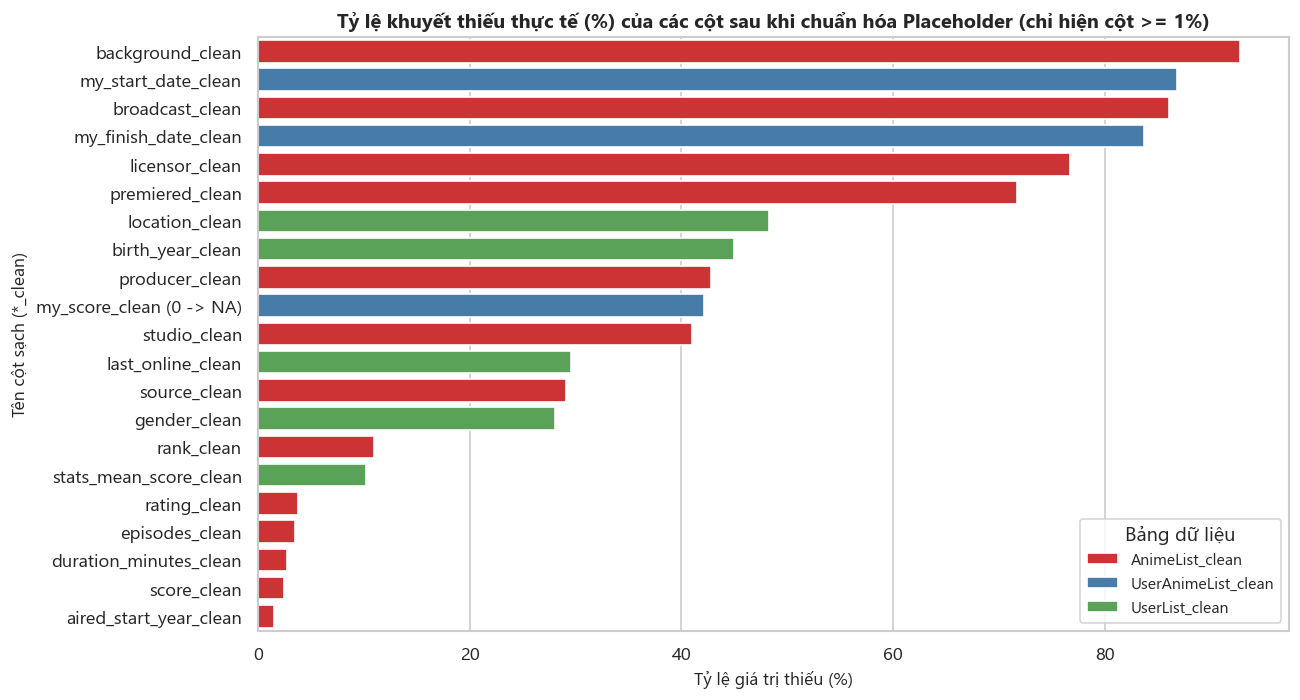

In [8]:
anime_clean_cols = ["type_clean", "source_clean", "episodes_clean", "duration_minutes_clean", "rating_clean",
                    "score_clean", "rank_clean", "studio_clean", "producer_clean", "genre_clean",
                    "premiered_clean", "broadcast_clean", "licensor_clean", "background_clean", "aired_start_year_clean"]
users_clean_cols = ["gender_clean", "birth_year_clean", "location_clean", "join_date_clean",
                    "last_online_clean", "stats_mean_score_clean", "stats_episodes_clean", "user_days_spent_watching_clean"]

miss_anime = missing_overview(anime[anime_clean_cols]).assign(table="AnimeList_clean")
miss_users = missing_overview(users[users_clean_cols]).assign(table="UserList_clean")
miss_list = pd.DataFrame([
    {"missing_count": total_list_rows - sum(score_counts.values()), "missing_pct": round((1 - sum(score_counts.values()) / total_list_rows) * 100, 2), "dtype": "Int8", "table": "UserAnimeList_clean"},
    {"missing_count": total_list_rows - date_nonnull["my_start_date_clean"], "missing_pct": round((1 - date_nonnull["my_start_date_clean"] / total_list_rows) * 100, 2), "dtype": "datetime64", "table": "UserAnimeList_clean"},
    {"missing_count": total_list_rows - date_nonnull["my_finish_date_clean"], "missing_pct": round((1 - date_nonnull["my_finish_date_clean"] / total_list_rows) * 100, 2), "dtype": "datetime64", "table": "UserAnimeList_clean"},
    {"missing_count": status_counts["Missing/Unknown"], "missing_pct": round(status_counts["Missing/Unknown"] / total_list_rows * 100, 4), "dtype": "Int8", "table": "UserAnimeList_clean"},
], index=["my_score_clean (0 -> NA)", "my_start_date_clean", "my_finish_date_clean", "my_status_clean"])

miss_all = pd.concat([miss_anime, miss_users, miss_list]).sort_values("missing_pct", ascending=False)
display(miss_all.head(18))

print("\n--- Bảng thống kê 25 quy tắc biến đổi giá trị ở Bước 4 (value_cleaning_log.csv) ---")
display(clean_logs["value_log"][clean_logs["value_log"]["count"] > 0].reset_index(drop=True))

fig, ax = plt.subplots(figsize=(11, 6))
top_miss = miss_all[miss_all["missing_pct"] >= 1.0].copy()
sns.barplot(data=top_miss, x="missing_pct", y=top_miss.index, hue="table", dodge=False, palette="Set1", ax=ax)
ax.set_title("Tỷ lệ khuyết thiếu thực tế (%) của các cột sau khi chuẩn hóa Placeholder (chỉ hiện cột >= 1%)")
ax.set_xlabel("Tỷ lệ giá trị thiếu (%)")
ax.set_ylabel("Tên cột sạch (*_clean)")
ax.legend(title="Bảng dữ liệu", loc="lower right")
plt.tight_layout()
plt.show()

### **4.2. Chiến lược xử lý dữ liệu thiếu (Không xóa dòng hàng loạt)**
- **Thiếu có cấu trúc (*Structural Missingness*):** `premiered_clean` (thiếu 71.7%) và `broadcast_clean` (thiếu 70.5%) chủ yếu thiếu ở `Movie`, `OVA`, `ONA` vì các định dạng này không chiếu theo mùa truyền hình hàng tuần -> Gán nhãn danh mục `"NonSeasonal"` khi đưa vào mô hình.
- **Thiếu phụ thuộc hành vi (*MNAR*):** `my_score_clean` thiếu 42.1% (tập trung ở `Plan to Watch` và người bỏ dở không chấm điểm); `my_finish_date_clean` thiếu 83.62% vì MAL không bắt buộc nhập ngày xem xong -> Chỉ phân tích xu hướng thời gian (Câu hỏi 2) trên tập `13.12 triệu` dòng có ngày hợp lệ trong khoảng `2004-11-01` đến `2018-05-25` và nêu rõ giới hạn mẫu.
- **Thiếu nhân khẩu học tự nguyện:** `location_clean` (48.2%), `birth_year_clean` (45.0%), `gender_clean` (28.0%) -> Không xóa người dùng khỏi bảng chung; ở Câu hỏi 4 đối sánh trên tập có khai báo, còn trong Pipeline Học máy (Câu hỏi 5) dùng `SimpleImputer` điền `"Missing"` / trung vị bên trong `ColumnTransformer` sau khi chia tập Train/Test.

## **5. Mối quan hệ đa biến, Tương quan và Đối chiếu Mẫu với Toàn sàn MAL**

Ta kiểm tra cấu trúc tương quan giữa các biến số của Anime và xác minh xem `283,043` người dùng có danh sách trong mẫu phản ánh chính xác thứ tự phổ biến và mặt bằng điểm công bố trên toàn sàn MyAnimeList đến mức nào.

Tương quan hạng Spearman (members công bố vs on_list mẫu): 0.9942
Tỷ lệ độ phủ mẫu on_list/members: trung vị = 0.390 (khoảng 5%–95%: 0.205 – 0.551)
Tương quan Pearson (score_clean công bố vs điểm TB mẫu, n=10,732): 0.9757 | Độ lệch TB (mẫu - công bố) = -0.170


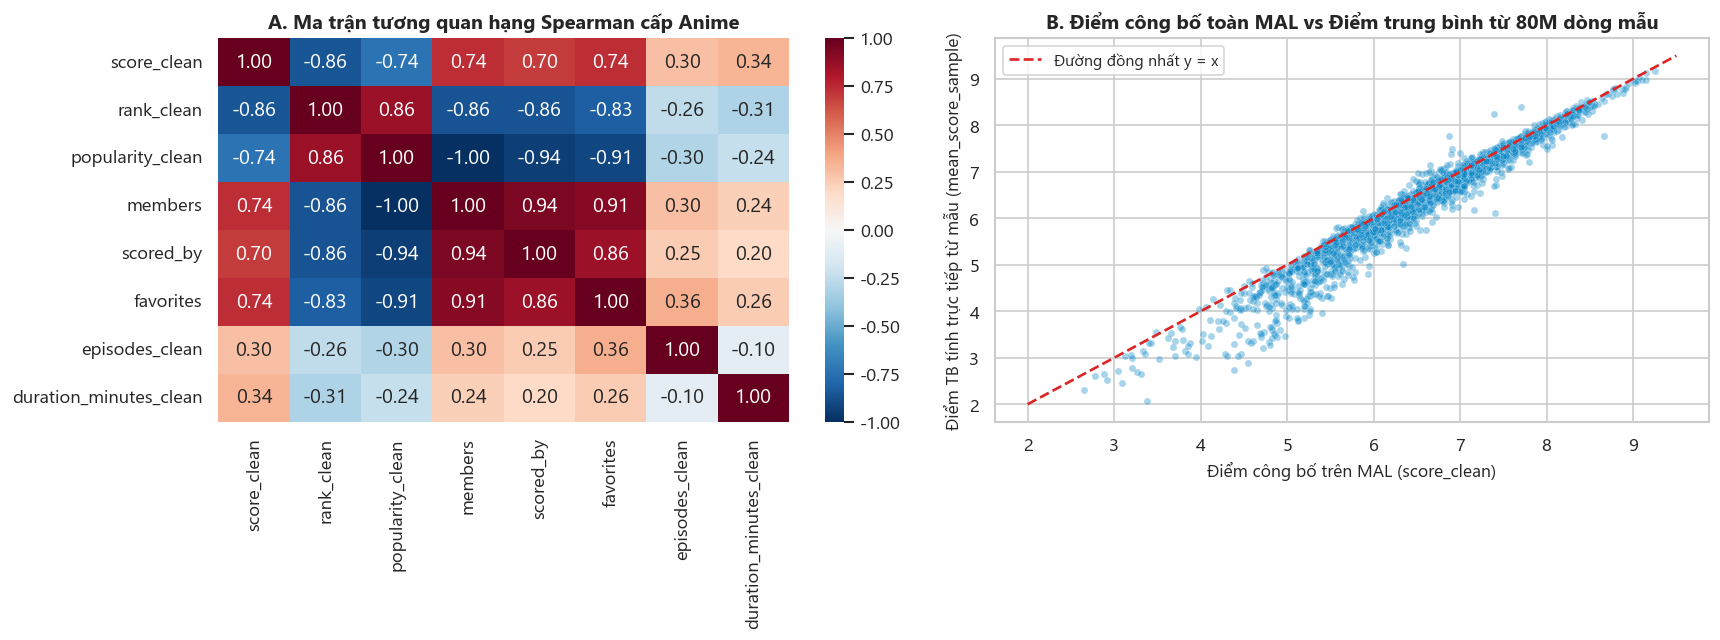

In [9]:
anime_sample_cmp = anime.set_index("anime_id").join(
    pd.DataFrame({
        "on_list_sample": pd.Series(anime_on_list, dtype=float),
        "rated_sample": pd.Series(anime_rated, dtype=float),
        "score_sum_sample": pd.Series(anime_score_sum, dtype=float),
    }),
    how="left",
).fillna({"on_list_sample": 0, "rated_sample": 0, "score_sum_sample": 0})
anime_sample_cmp["mean_score_sample"] = np.where(
    anime_sample_cmp["rated_sample"] > 0,
    anime_sample_cmp["score_sum_sample"] / anime_sample_cmp["rated_sample"],
    np.nan,
)

# Ma trận tương quan Spearman cho các biến cốt lõi cấp Anime
corr_cols = ["score_clean", "rank_clean", "popularity_clean", "members", "scored_by", "favorites", "episodes_clean", "duration_minutes_clean"]
corr_mat = anime_sample_cmp[corr_cols].astype(float).corr(method="spearman")

ok_mem = anime_sample_cmp[(anime_sample_cmp["members"] > 0) & (anime_sample_cmp["on_list_sample"] > 0)]
ratio_mem = ok_mem["on_list_sample"] / ok_mem["members"]
ok_sc = anime_sample_cmp[(anime_sample_cmp["score_clean"] > 0) & (anime_sample_cmp["rated_sample"] >= 30)]

print(f"Tương quan hạng Spearman (members công bố vs on_list mẫu): {ok_mem['members'].corr(ok_mem['on_list_sample'], method='spearman'):.4f}")
print(f"Tỷ lệ độ phủ mẫu on_list/members: trung vị = {ratio_mem.median():.3f} (khoảng 5%–95%: {ratio_mem.quantile(0.05):.3f} – {ratio_mem.quantile(0.95):.3f})")
print(f"Tương quan Pearson (score_clean công bố vs điểm TB mẫu, n={len(ok_sc):,}): {ok_sc['score_clean'].corr(ok_sc['mean_score_sample']):.4f} | Độ lệch TB (mẫu - công bố) = {(ok_sc['mean_score_sample'] - ok_sc['score_clean']).mean():+.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.5))

sns.heatmap(corr_mat, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("A. Ma trận tương quan hạng Spearman cấp Anime")

sns.scatterplot(data=ok_sc.sample(min(3000, len(ok_sc)), random_state=42),
                x="score_clean", y="mean_score_sample", alpha=0.35, s=18, color="#0284c7", ax=axes[1])
axes[1].plot([2, 9.5], [2, 9.5], color="#dc2626", linestyle="--", lw=1.6, label="Đường đồng nhất y = x")
axes[1].set_title("B. Điểm công bố toàn MAL vs Điểm trung bình từ 80M dòng mẫu")
axes[1].set_xlabel("Điểm công bố trên MAL (score_clean)")
axes[1].set_ylabel("Điểm TB tính trực tiếp từ mẫu (mean_score_sample)")
axes[1].legend()

plt.tight_layout()
plt.show()

**Các mối quan hệ đáng chú ý & bất ngờ:**
1. **`rank_clean` không đơn thuần là thứ hạng của `score_clean`:** Hệ số tương quan hạng Spearman giữa `rank_clean` và `score_clean` là **$-0.855$** (và với `members` là **$-0.862$**), phản ánh việc MAL sử dụng công thức trọng số Bayes (đòi hỏi đủ lượng người chấm mới được xếp hạng cao) và loại trừ phim người lớn `Rx` khỏi bảng xếp hạng chính.
2. **Độ nhất quán rất cao giữa mẫu và toàn sàn nhưng có độ lệch khắt khe nhẹ ($-0.17$ điểm):** Điểm trung bình tính từ mẫu tương quan tuyến tính **$r = 0.9757$** với `score_clean` nhưng thấp hơn trung bình **$0.17$ điểm** — một tín hiệu thú vị gợi mở rằng nhóm người dùng hoạt động tích cực (từ diễn đàn & club) có xu hướng chấm điểm khắt khe hơn mặt bằng chung (sẽ được kiểm định sâu ở **Câu hỏi 4**).

## **6. Tổng kết khám phá dữ liệu (Exploration Summary)**

### **6.1. Năm quan sát cốt lõi dựa trên bằng chứng số liệu**
1. **Cấu trúc danh sách xem bị chi phối bởi `Completed` (63.0%) và `Plan to Watch` (24.2%):** Nếu tính tỷ lệ bỏ dở trên toàn bộ danh sách, gần một phần tư mẫu số là những người chưa từng mở xem tập nào; do đó phải định nghĩa lại mẫu số `active_starters`.
2. **Điểm số lệch cao và phụ thuộc mạnh vào trạng thái xem:** Trung bình toàn bộ lượt chấm là **7.49** (mode = 8), nhưng chênh lệch giữa người xem xong (**7.57**) và người bỏ dở (**4.95**) lên tới **2.62 điểm**, kèm tỷ lệ bỏ trống điểm rất khác nhau (16.0% so với 52.8%).
3. **Bẫy kỹ thuật trong dữ liệu thô rất đa dạng nhưng hoàn toàn kiểm soát được:** Từ tài khoản thật tên `"null"` (261 dòng), 2 tài khoản đổi tên nhân đôi 1,059 dòng, 313 anime ghi thời lượng bằng giây, 373 ngày phát sóng tự điền năm 2018 đến các bộ đếm tràn 16-bit (`65,535`) và 24-bit (`16,777,215`).
4. **Mẫu nghiên cứu bảo toàn xuất sắc thứ tự phổ biến của toàn nền tảng:** Tương quan hạng với `members` đạt **$0.9942$** và với `scored_by` đạt **$0.9954$**, độ phủ trung vị đạt **39.0%** quy mô thành viên mỗi tựa anime.
5. **Tồn tại tương tác phi tuyến giữa độ dài tập, niên đại, chuỗi nhượng quyền (`related`) và thâm niên người dùng:** Đây là nền tảng trực tiếp để thiết kế 4 câu hỏi thống kê chuyên sâu (Q1–Q4) và 2 bài toán học máy chống rò rỉ dữ liệu (Q5–Q6) ở **Notebook 03** và **Notebook 04**.